# Student notebook — Solving Differential Equations with Differentiable Quantum Circuits

The notebook is inspired by Kyriienko, Paine and Elfving, *Solving nonlinear differential equations with differentiable quantum circuits* (arXiv:2011.10395).

Complete every block marked **`TODO`** and answer the Markdown questions in the indicated answer boxes.

> **Important.** The goal is not to reproduce the numerical values of the paper exactly. The experiments are deliberately smaller than the paper so they can be run on a laptop.


In [1]:
# If needed, install in a clean environment:
%pip install qiskit qiskit-machine-learning qiskit-algorithms

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from numpy.polynomial import chebyshev as cheb

SEED = 7
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=5, suppress=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00


## Part I — Classical Chebyshev approximation

The target from Figure 4 is

$$
y(x)=\begin{cases}
\exp\!\left(-\frac{1}{25x^2}\right)\cos(20x), & x\neq 0,\\
0, & x=0.
\end{cases}
$$

### Q1
Plot the target on a dense grid. What makes it nontrivial to approximate? Comment on the oscillations and on the behavior near $x=0$.

**Your answer:**

> TODO

### Q2–Q3
Fit Chebyshev expansions using 2, 16 and 64 basis functions. Plot them with the target and report the MSE and maximum absolute error.


/tmp/ipykernel_431/2046256235.py:7: RuntimeWarning: divide by zero encountered in divide
  envelope = np.exp(-1/(25*x**2))*np.cos(20*x)


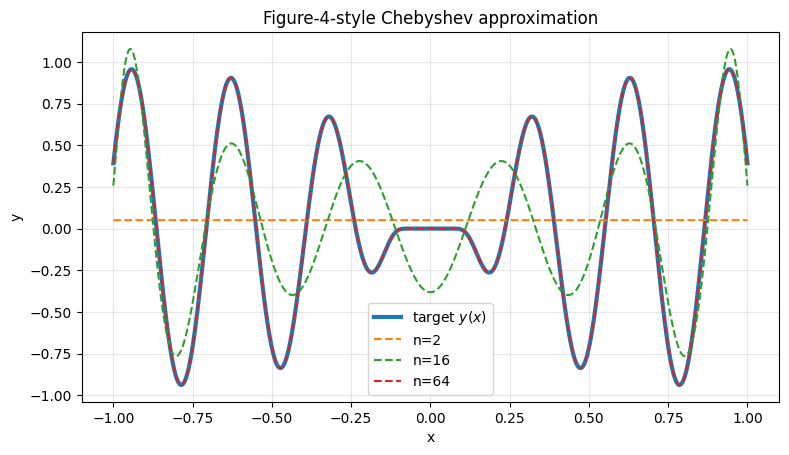

,n_basis,MSE,max_abs_error
0,2,Ellipsis,Ellipsis
1,16,Ellipsis,Ellipsis
2,64,Ellipsis,Ellipsis


In [19]:
def y_target(x):
    x = np.asarray(x, dtype=float)
    # TODO 1: compute exp(-1/(25*x**2)) safely for x != 0.
    # TODO 2: impose the continuous extension envelope(0) = 0.
    with np.errstate(divide="ignore", invalid="ignore"):
        envelope = np.where(x == 0, 0, np.exp(-1/(25*x**2))*np.cos(20*x))
    envelope = np.exp(-1/(25*x**2))*np.cos(20*x)
    return envelope

x_dense = np.linspace(-1, 1, 1201)  # includes x=0 exactly
y_dense = y_target(x_dense)

basis_sizes = [2, 16, 64]
fits = {}
rows = []
for n in basis_sizes:
    # TODO 3: fit degrees 0,...,n-1 with cheb.chebfit.
    coef = cheb.chebfit(x_dense, y_dense, deg=n-1)
    # TODO 4: evaluate the expansion with cheb.chebval.
    y_hat = cheb.chebval(x_dense, coef)
    fits[n] = y_hat
    rows.append({
        "n_basis": n,
        "MSE": ...,              # TODO
        "max_abs_error": ...,    # TODO
    })

plt.figure(figsize=(9,4.8))
plt.plot(x_dense, y_dense, linewidth=3, label="target $y(x)$")
for n in basis_sizes:
    plt.plot(x_dense, fits[n], "--", label=f"n={n}")
plt.xlabel("x"); plt.ylabel("y")
plt.title("Figure-4-style Chebyshev approximation")
plt.grid(alpha=.3); plt.legend(); plt.show()

pd.DataFrame(rows)

### Q4
Why are Chebyshev polynomials particularly suitable for smooth-function approximation on a bounded interval? Mention expressivity and numerical/spectral considerations. Does the non-analytic point at $x=0$ change what convergence rate you expect asymptotically?

**Your answer:**

> They are suitable for smooth-function approximation because they minimise error on approximation. Moreover they are bounded between [-1, 1] so they are stable. The non-analytic point at x = 0 changes consequently the convergence speed.

## Part II — Quantum feature maps and differentiable quantum functions

We use one scalar circuit input `z`, after a classical nonlinear transform:

- Product: $z=\arcsin x$, with $R_y(z)$ on every qubit.
- Cheb: $z=2\arccos x$, with $R_y(z)$ on every qubit.
- ChebT: $z=2\arccos x$, with $R_y((j+1)z)$ on qubit $j$.

### Q5
Complete the transformations and the QNN construction below. Draw the three feature-map circuits. In what precise sense is ChebT more expressive than Cheb at fixed qubit count?


In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN


def feature_transform(x, kind):
    x = np.asarray(x, dtype=float)
    if kind == "prod":
        # TODO: Product transform
        return ...
    if kind in ("cheb", "chebt"):
        # TODO: Chebyshev transform
        return ...
    raise ValueError(kind)


def feature_transform_prime(x, kind):
    x = np.asarray(x, dtype=float)
    den = np.sqrt(np.maximum(1e-12, 1.0-x*x))
    if kind == "prod":
        # TODO: derivative of arcsin(x)
        return ...
    if kind in ("cheb", "chebt"):
        # TODO: derivative of 2 arccos(x)
        return ...
    raise ValueError(kind)


def build_qnn(kind="chebt", n_qubits=3, depth=2):
    z = Parameter("z")
    qc = QuantumCircuit(n_qubits)

    # Feature map
    for q in range(n_qubits):
        # TODO: ChebT uses degree ladder 1,2,...,N; others use multiplier 1.
        mult = ...
        qc.ry(..., q)  # TODO: angle

    # Hardware-efficient ansatz: Rz --> Ry --> Rz + linear/ring entanglement
    theta = ParameterVector("theta", length=3*n_qubits*depth)
    k = 0
    for _ in range(depth):
        for q in range(n_qubits):
            qc.rz(theta[k], q); k += 1
            qc.ry(theta[k], q); k += 1
            qc.rz(theta[k], q); k += 1
        for q in range(n_qubits-1):
            qc.cx(q, q+1)
        if n_qubits > 2:
            qc.cx(n_qubits-1, 0)

    # TODO: normalized total magnetization C = (1/N) sum_j Z_j.
    observable = SparsePauliOp.from_sparse_list(
        ...,  # list of ("Z", [q], coefficient) terms
        num_qubits=n_qubits,
    )

    estimator = StatevectorEstimator(seed=SEED)
    qnn = EstimatorQNN(
        circuit=qc,
        estimator=estimator,
        observables=observable,
        input_params=[z],
        weight_params=list(theta),
        input_gradients=True,
    )
    return qc, qnn

# Test your construction.
qc_demo, qnn_demo = build_qnn("chebt", 3, 2)
print(qc_demo.draw(output="text"))
print("number of trainable weights:", qnn_demo.num_weights)

**Your Q5 answer:**

> TODO: explain the degree ladder and why richer representation does not automatically imply easier optimization.

### Q6–Q7
Plot random quantum functions for the three feature maps. Then compute $dq_\theta/dx$ using the QNN input gradient and the classical chain rule, and compare it with centered finite differences.


In [ ]:
def q_and_dqdx(qnn, weights, x, kind):
    x = np.asarray(x, dtype=float)
    z = feature_transform(x, kind)
    q = np.asarray(qnn.forward(z[:, None], weights)).reshape(-1)

    # EstimatorQNN.backward returns (input_grad, weight_grad).
    input_grad, _ = qnn.backward(z[:, None], weights)
    dq_dz = np.asarray(input_grad).reshape(len(x), -1)[:, 0]

    # TODO: apply the chain rule dq/dx = (dq/dz)(dz/dx).
    dq_dx = ...
    return q, dq_dx

xq = np.linspace(0.0, 0.9, 250)
plt.figure(figsize=(9,4.8))
for kind in ["prod", "cheb", "chebt"]:
    _, qnn = build_qnn(kind, n_qubits=3, depth=2)
    w = rng.normal(scale=0.25, size=qnn.num_weights)
    q, _ = q_and_dqdx(qnn, w, xq, kind)
    plt.plot(xq, q, label=kind)
plt.xlabel("x"); plt.ylabel(r"$q_\theta(x)$")
plt.title("Random quantum functions induced by different feature maps")
plt.grid(alpha=.3); plt.legend(); plt.show()

In [ ]:
# Q7: analytic/QNN input derivative versus centered finite differences
kind = "chebt"
_, qnn = build_qnn(kind, n_qubits=3, depth=2)
w = rng.normal(scale=0.3, size=qnn.num_weights)
test_x = np.array([0.12, 0.33, 0.57, 0.81])
_, dq_exact = q_and_dqdx(qnn, w, test_x, kind)

rows = []
for h in [1e-2, 3e-3, 1e-3, 3e-4, 1e-4]:
    qp, _ = q_and_dqdx(qnn, w, test_x+h, kind)
    qm, _ = q_and_dqdx(qnn, w, test_x-h, kind)
    # TODO: centered finite-difference derivative.
    dq_fd = ...
    rows.append({
        "h": h,
        "max |analytic-FD|": ...,  # TODO: maximum discrepancy
    })

pd.DataFrame(rows)

### Q8
Why is an analytic/automatic derivative of the circuit attractive for a differential-equation solver? What changes on shot-based noisy hardware?

**Your answer:**

> TODO


## Part III — Physics-informed DQC loss

Use the pinned model

$$\tilde u_\theta(x)=u_0+s x q_\theta(x).$$

### Q9
Derive $d\tilde u_\theta/dx$ and implement it below.

**Derivation:**

> TODO: write the derivative explicitly before coding it.


In [ ]:
U0 = 1.0
KAPPA = 0.1
OUTPUT_SCALE = 5.0


def exact_solution(x, lam, u0=U0, kappa=KAPPA):
    x = np.asarray(x)
    # TODO: analytical solution of the benchmark ODE.
    return ...


def safe_collocation(lam, m=14, xmax=0.9, pole_tol=0.055):
    # Remove points too close to poles of tan(lam*x).
    candidates = np.linspace(0.02, xmax, 4*m)
    ok = np.abs(np.cos(lam*candidates)) > pole_tol
    pts = candidates[ok]
    idx = np.linspace(0, len(pts)-1, m).round().astype(int)
    return np.unique(pts[idx])


def trial_and_derivative(qnn, weights, x, kind, scale=OUTPUT_SCALE):
    q, dqdx = q_and_dqdx(qnn, weights, x, kind)
    x = np.asarray(x)
    # TODO: pinned trial solution u0 + s*x*q(x).
    u = ...
    # TODO: derivative from your Q9 derivation.
    dudx = ...
    return u, dudx


def differential_loss(qnn, weights, xcol, kind, lam):
    u, dudx = trial_and_derivative(qnn, weights, xcol, kind)
    # TODO: residual r = u' + lambda*u*(kappa + tan(lambda*x)).
    residual = ...
    return float(...)  # TODO: mean squared residual


def quality_loss(qnn, weights, xtest, kind, lam):
    u, _ = trial_and_derivative(qnn, weights, xtest, kind)
    # Diagnostic only: do NOT use this loss for training.
    return float(...)  # TODO: MSE against exact_solution


### Q10–Q12
Complete the training routine. Train a ChebT model for $\lambda=8$, plot the learned/exact solutions and the two losses, then repeat for $\lambda=20$.


In [ ]:
def train_dqc(kind="chebt", lam=8.0, n_qubits=3, depth=2,
              maxiter=90, seed=SEED, m_collocation=14, verbose=False):
    local_rng = np.random.default_rng(seed)
    qc, qnn = build_qnn(kind, n_qubits=n_qubits, depth=depth)
    w0 = local_rng.normal(scale=0.15, size=qnn.num_weights)
    xcol = safe_collocation(lam, m=m_collocation)
    xtest = np.linspace(0, 0.9, 220)
    history = []
    t0 = time.perf_counter()

    def objective(w):
        # TODO: physics-informed loss only.
        return ...

    def callback(w):
        history.append({
            "LF": objective(w),
            "LQ": quality_loss(qnn, w, xtest, kind, lam),
        })
        if verbose and len(history) % 10 == 0:
            print(len(history), history[-1])

    result = minimize(
        objective, w0,
        method=...,  # TODO: use "COBYLA" for this first experiment
        callback=callback,
        options={"maxiter": maxiter, "rhobeg": 0.25, "tol": 1e-5},
    )
    elapsed = time.perf_counter()-t0
    if not history:
        callback(result.x)
    return {
        "kind": kind, "lam": lam, "depth": depth, "n_qubits": n_qubits,
        "qc": qc, "qnn": qnn, "result": result, "weights": result.x,
        "xcol": xcol, "xtest": xtest, "history": pd.DataFrame(history),
        "elapsed": elapsed,
    }

# TODO: train lambda=8 with ChebT. (Laptop-friendly first training run. Increase maxiter to 150-300 for a cleaner fit.)
run8 = ...

# Plot the solution once run8 exists.
u8, _ = trial_and_derivative(run8["qnn"], run8["weights"], run8["xtest"], "chebt")
plt.figure(figsize=(8.5,4.6))
plt.plot(run8["xtest"], exact_solution(run8["xtest"],8), linewidth=3, label="exact")
plt.plot(run8["xtest"], u8, "--", label="DQC ChebT")
plt.scatter(run8["xcol"], exact_solution(run8["xcol"],8), s=22, label="collocation locations")
plt.xlabel("x"); plt.ylabel("u(x)"); plt.title(r"DQC ODE solution, $\lambda=8$")
plt.grid(alpha=.3); plt.legend(); plt.show()

run8["history"].plot(logy=True, figsize=(8.5,4.5), title="Training diagnostics")
plt.xlabel("optimizer callback"); plt.ylabel("loss"); plt.grid(alpha=.3); plt.show()

# TODO: repeat for lambda=20 and make analogous plots.
run20 = ...


**Q10–Q12 — Your discussion:**

> TODO: Explain what $L_F$ and $L_Q$ measure, why they need not decrease at the same rate, and why $\lambda=20$ is harder than $\lambda=8$.


## Part IV — Feature-map comparison (Figure-6-style)

### Q13–Q16
Keep the qubit count, ansatz depth, collocation protocol, optimizer budget and initialization protocol as comparable as possible. Train Product, Cheb and ChebT for $\lambda=8$ and $\lambda=20$.


In [ ]:
# This cell can take a few minutes depending on the machine.
runs = {}
for lam in [8, 20]:
    for i, kind in enumerate(["prod", "cheb", "chebt"]):
        print("training", lam, kind)
        # TODO: call train_dqc with a controlled/common configuration.
        runs[(lam,kind)] = ...

# Figure-6-style solution comparison.
fig, axes = plt.subplots(1,2,figsize=(12,4.3), sharey=False)
for ax, lam in zip(axes, [8,20]):
    x = np.linspace(0,0.9,300)
    ax.plot(x, exact_solution(x,lam), linewidth=3, label="exact")
    for kind in ["prod","cheb","chebt"]:
        r = runs[(lam,kind)]
        up, _ = trial_and_derivative(r["qnn"], r["weights"], x, kind)
        ax.plot(x, up, "--", label=kind)
    ax.set_title(fr"$\lambda={lam}$")
    ax.set_xlabel("x"); ax.set_ylabel("u(x)"); ax.grid(alpha=.3); ax.legend()
plt.suptitle("Figure-6-style comparison: feature-map expressivity")
plt.tight_layout(); plt.show()

# TODO: create the two-panel log-scale convergence figure using LF and LQ.
# Hint: each run stores a pandas DataFrame in r["history"].
...

# TODO: summarize final LF, LQ and runtime in a DataFrame.
summary = []
for (lam,kind), r in runs.items():
    h = r["history"]
    summary.append({
        "lambda": lam,
        "feature_map": kind,
        "final_LF": ...,
        "final_LQ": ...,
        "seconds": ...,
    })
pd.DataFrame(summary).sort_values(["lambda","feature_map"])


**Q13–Q16 — Your discussion:**

> TODO: Compare the three feature maps for both values of $\lambda$. Discuss representation capacity versus trainability. Then compare your qualitative observations with Figure 6 of the paper without claiming exact numerical reproduction.


## Part V — Ansatz-depth study

### Q17–Q19
Fix $\lambda=20$ and ChebT. Compare at least three ansatz depths, for example $d=1,2,4$.


In [ ]:
depth_runs = {}
for d in [1,2,4]:
    print("depth", d)
    # TODO: train a ChebT model for lambda=20 at depth d.
    depth_runs[d] = ...

# TODO: plot exact solution and all depth-dependent learned solutions.
...

# TODO: produce a log-scale convergence plot (at least LQ; ideally LF and LQ).
...

# Build the summary table.
rows=[]
for d,r in depth_runs.items():
    h=r["history"]
    rows.append({
        "depth": d,
        "n_weights": ...,        # TODO
        "final_LF": ...,         # TODO
        "final_LQ": ...,         # TODO
        "seconds": ...,          # TODO
    })
pd.DataFrame(rows)


**Q17–Q19 — Your discussion:**

> TODO: Explain the trade-off between expressivity, number of trainable parameters, circuit/evaluation cost, optimizer difficulty, and possible flat-gradient/barren-plateau behavior.
